# Olist E-Commerce Sales Analysis (SQL + Python)

**Goal:** analyze ~96K real orders from Olist, a Brazilian online marketplace (2017–2018), to answer five business questions about revenue, products, delivery, customer loyalty and payments.

**Tools:** Python (Pandas, Matplotlib, Seaborn), SQL (SQLite), Jupyter Notebook

**Steps:** load 8 related tables → clean the data with Pandas → load it into a SQL database → answer business questions with SQL → visualize the results → write insights.

## 1. Setup and data loading

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
COLOR = "#1F3864"
DATA = "data/"   # folder with the Kaggle CSV files

orders    = pd.read_csv(DATA + "olist_orders_dataset.csv")
items     = pd.read_csv(DATA + "olist_order_items_dataset.csv")
customers = pd.read_csv(DATA + "olist_customers_dataset.csv")
reviews   = pd.read_csv(DATA + "olist_order_reviews_dataset.csv")
payments  = pd.read_csv(DATA + "olist_order_payments_dataset.csv")
products  = pd.read_csv(DATA + "olist_products_dataset.csv")
translate = pd.read_csv(DATA + "product_category_name_translation.csv")

for name, df in {"orders": orders, "items": items, "customers": customers, "reviews": reviews,
                 "payments": payments, "products": products}.items():
    print(f"{name:10} {df.shape[0]:>7,} rows  {df.shape[1]:>2} columns")

orders      99,441 rows   8 columns
items      112,650 rows   7 columns
customers   99,441 rows   5 columns
reviews     99,224 rows   7 columns
payments   103,886 rows   5 columns
products    32,951 rows   9 columns


## 2. Data cleaning (Pandas)

In [2]:
# Missing values in the orders table
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [3]:
# 1) Convert date columns from text to datetime
date_cols = [c for c in orders.columns if "date" in c or "timestamp" in c or c == "order_approved_at"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

# 2) Keep full months only: Jan 2017 - Aug 2018 (the months before/after have almost no orders)
before = len(orders)
orders = orders[(orders.order_purchase_timestamp >= "2017-01-01") &
                (orders.order_purchase_timestamp <  "2018-09-01")]
print(f"Removed {before - len(orders):,} orders outside Jan 2017 - Aug 2018")

# 3) Some orders have more than one review -> keep the latest review per order
before = len(reviews)
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])
reviews = (reviews.sort_values("review_answer_timestamp")
                  .drop_duplicates("order_id", keep="last"))
print(f"Removed {before - len(reviews):,} duplicate reviews")

# 4) Translate product categories to English and fill missing ones
extra = pd.DataFrame({"product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
                      "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers"]})
translate = pd.concat([translate, extra])
products = products.merge(translate, on="product_category_name", how="left")
products["category"] = products["product_category_name_english"].fillna("unknown")
print(f"Products with unknown category: {(products.category == 'unknown').sum():,}")

# 5) Keep only rows that belong to the orders we kept
kept = set(orders.order_id)
items    = items[items.order_id.isin(kept)]
reviews  = reviews[reviews.order_id.isin(kept)]
payments = payments[payments.order_id.isin(kept)]

print(f"Duplicate order rows: {orders.duplicated().sum()}")
print(f"Orders after cleaning: {len(orders):,}  |  delivered: {(orders.order_status == 'delivered').sum():,}")

Removed 349 orders outside Jan 2017 - Aug 2018
Removed 551 duplicate reviews
Products with unknown category: 610


Duplicate order rows: 0
Orders after cleaning: 99,092  |  delivered: 96,211


## 3. Load the clean data into a SQL database (SQLite)

In [4]:
con = sqlite3.connect("olist.db")
orders.to_sql("orders", con, if_exists="replace", index=False)
items.to_sql("order_items", con, if_exists="replace", index=False)
customers.to_sql("customers", con, if_exists="replace", index=False)
reviews.to_sql("reviews", con, if_exists="replace", index=False)
payments.to_sql("payments", con, if_exists="replace", index=False)
products[["product_id", "category"]].to_sql("products", con, if_exists="replace", index=False)

def q(sql):
    """Run a SQL query and return the result as a DataFrame."""
    return pd.read_sql(sql, con)

q("SELECT name FROM sqlite_master WHERE type = 'table'")

,name
0,orders
1,order_items
2,customers
3,reviews
4,payments
5,products


## 4. Business questions

### Q1. How did monthly revenue change over time?

In [5]:
q1 = q("""
WITH monthly AS (
    SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month,
           COUNT(DISTINCT o.order_id)                     AS orders,
           ROUND(SUM(i.price), 2)                         AS revenue
    FROM orders o
    JOIN order_items i ON o.order_id = i.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY month
)
SELECT month,
       orders,
       revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month))
             / LAG(revenue) OVER (ORDER BY month), 1) AS mom_growth_pct
FROM monthly
ORDER BY month;
""")
q1

,month,orders,revenue,mom_growth_pct
0,2017-01,750,111798.36,NaN
1,2017-02,1653,234223.40,109.5
2,2017-03,2546,359198.85,53.4
3,2017-04,2303,340669.68,-5.2
4,2017-05,3546,489338.25,43.6
5,2017-06,3135,421923.37,-13.8
6,2017-07,3872,481604.52,14.1
7,2017-08,4193,554699.70,15.2
8,2017-09,4150,607399.67,9.5
9,2017-10,4478,648247.65,6.7


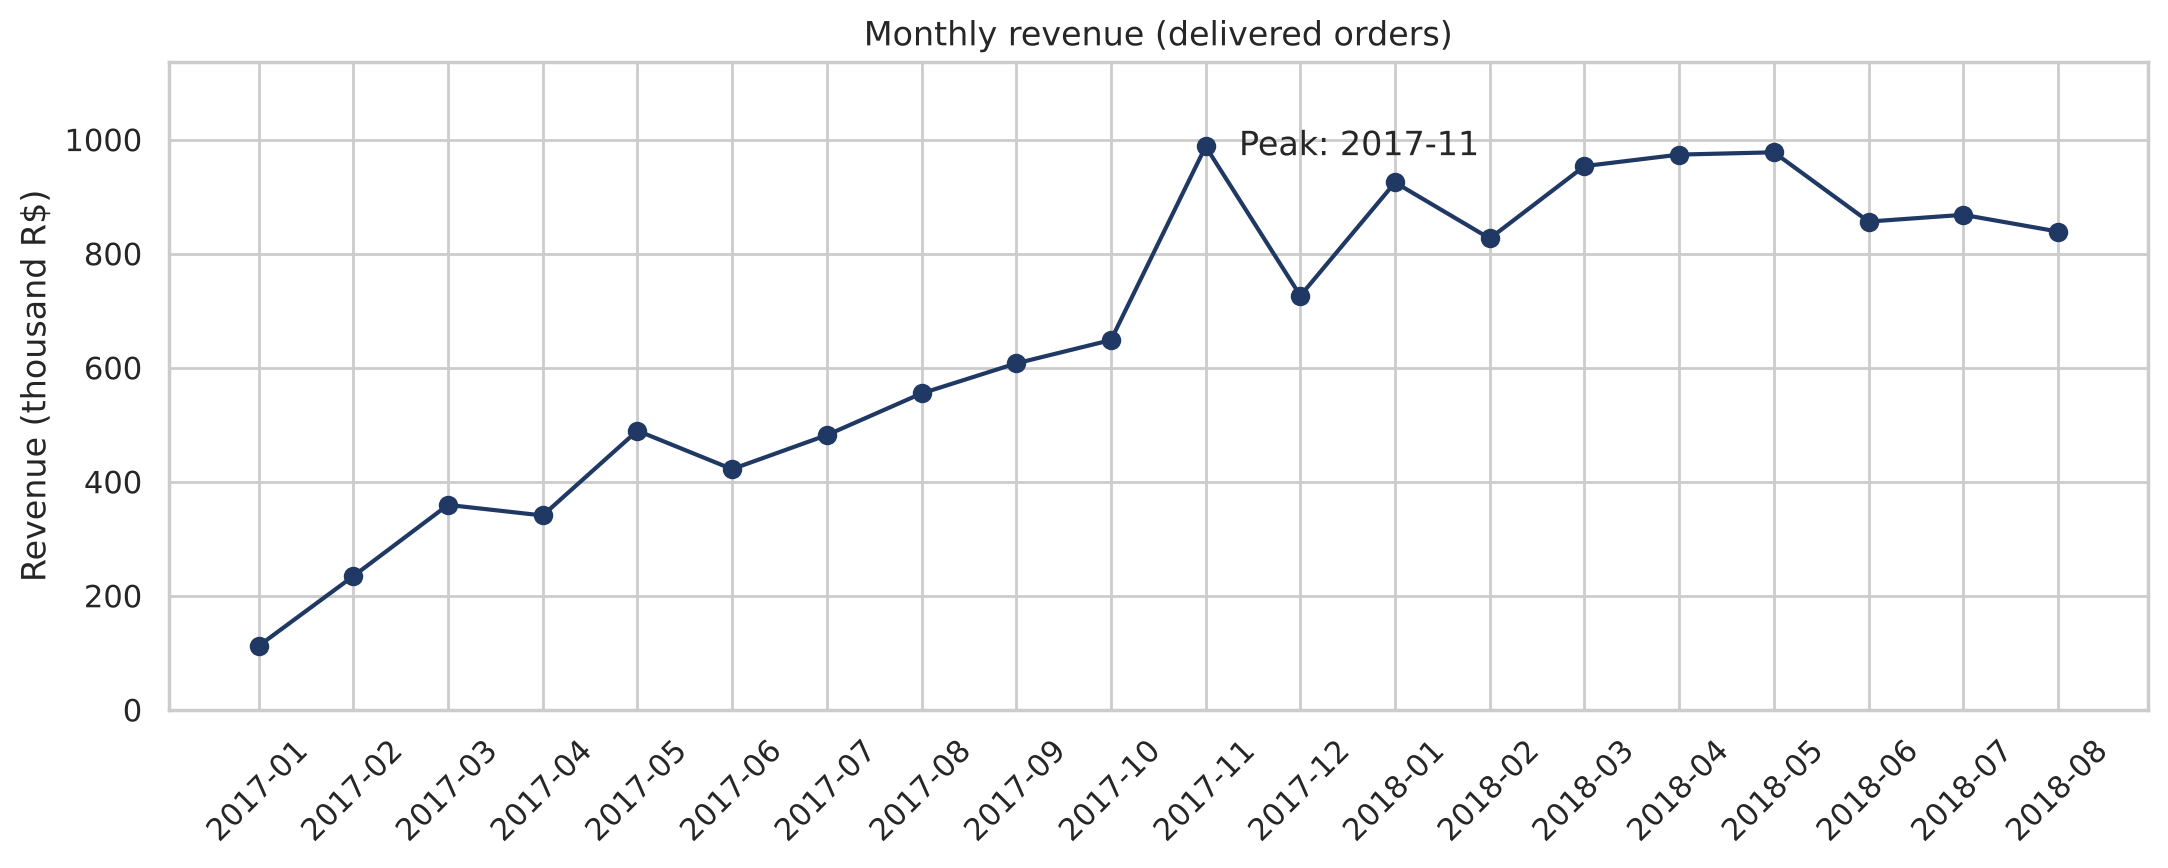

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(q1.month, q1.revenue / 1000, marker="o", color=COLOR)
peak = q1.loc[q1.revenue.idxmax()]
ax.annotate(f"Peak: {peak.month}", (peak.month, peak.revenue / 1000),
            textcoords="offset points", xytext=(12, 0), ha="left", va="center")
ax.set_ylim(0, q1.revenue.max() / 1000 * 1.15)
ax.set_title("Monthly revenue (delivered orders)")
ax.set_ylabel("Revenue (thousand R$)")
ax.set_xlabel("")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("images/q1_monthly_revenue.png", dpi=150)
plt.show()

### Q2. Which 10 product categories bring the most revenue?

In [7]:
q2 = q("""
SELECT p.category,
       COUNT(DISTINCT i.order_id)                                AS orders,
       ROUND(SUM(i.price), 2)                                    AS revenue,
       ROUND(100.0 * SUM(i.price) / SUM(SUM(i.price)) OVER (), 1) AS revenue_share_pct
FROM order_items i
JOIN orders   o ON i.order_id   = o.order_id
JOIN products p ON i.product_id = p.product_id
WHERE o.order_status = 'delivered'
GROUP BY p.category
ORDER BY revenue DESC
LIMIT 10;
""")
q2

,category,orders,revenue,revenue_share_pct
0,health_beauty,8610,1229557.50,9.3
1,watches_gifts,5491,1163465.91,8.8
2,bed_bath_table,9267,1022955.77,7.8
3,sports_leisure,7513,952840.40,7.2
4,computers_accessories,6518,888055.59,6.7
5,furniture_decor,6258,706237.17,5.4
6,housewares,5734,614341.62,4.7
7,cool_stuff,3552,609158.00,4.6
8,auto,3802,577838.39,4.4
9,garden_tools,3443,469135.40,3.6


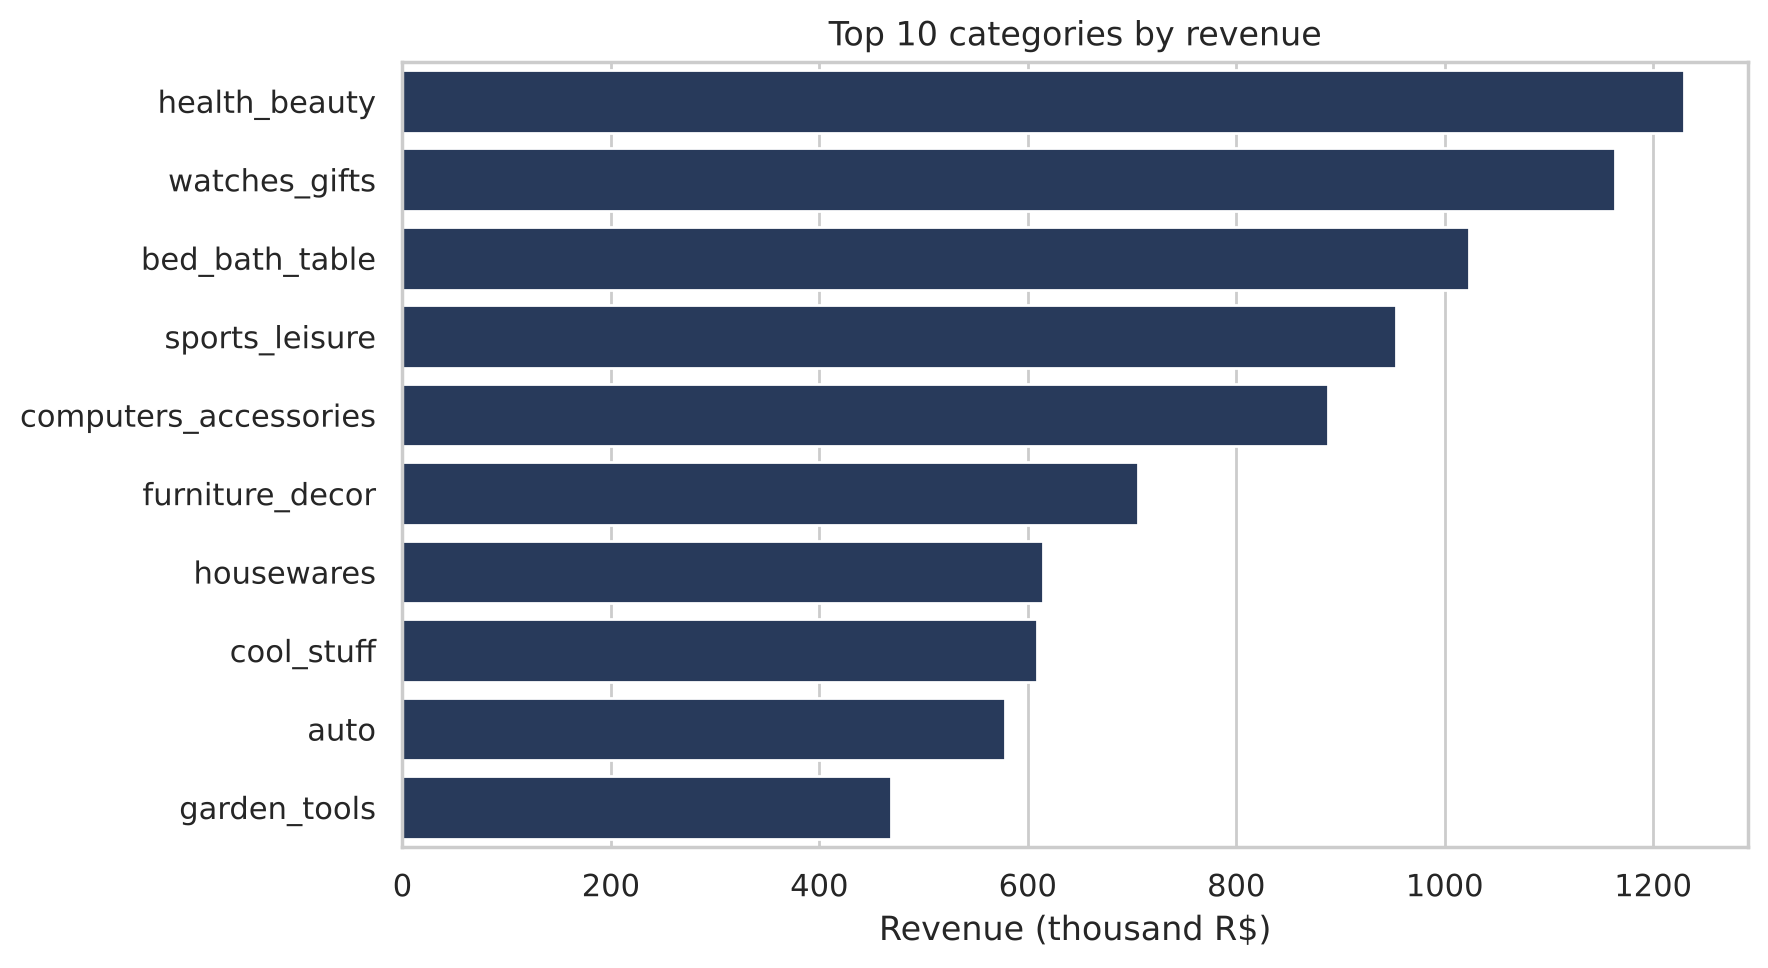

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=q2, y="category", x=q2.revenue / 1000, color=COLOR, ax=ax)
ax.set_title("Top 10 categories by revenue")
ax.set_xlabel("Revenue (thousand R$)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("images/q2_top_categories.png", dpi=150)
plt.show()

### Q3. Do late deliveries lower customer review scores?

In [9]:
q3 = q("""
WITH deliveries AS (
    SELECT o.order_id,
           julianday(date(o.order_delivered_customer_date))
         - julianday(date(o.order_estimated_delivery_date)) AS days_late,
           r.review_score
    FROM orders o
    JOIN reviews r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
)
SELECT CASE
           WHEN days_late <= 0  THEN '1. On time'
           WHEN days_late <= 7  THEN '2. 1-7 days late'
           WHEN days_late <= 14 THEN '3. 8-14 days late'
           ELSE                      '4. 15+ days late'
       END                                        AS delivery_status,
       COUNT(*)                                   AS orders,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_orders,
       ROUND(AVG(review_score), 2)                AS avg_review_score,
       ROUND(100.0 * AVG(review_score <= 2), 1)   AS pct_bad_reviews
FROM deliveries
GROUP BY delivery_status
ORDER BY delivery_status;
""")
q3

,delivery_status,orders,pct_of_orders,avg_review_score,pct_bad_reviews
0,1. On time,89182,93.3,4.29,9.2
1,2. 1-7 days late,3599,3.8,2.71,49.4
2,3. 8-14 days late,1446,1.5,1.67,80.2
3,4. 15+ days late,1333,1.4,1.72,78.3


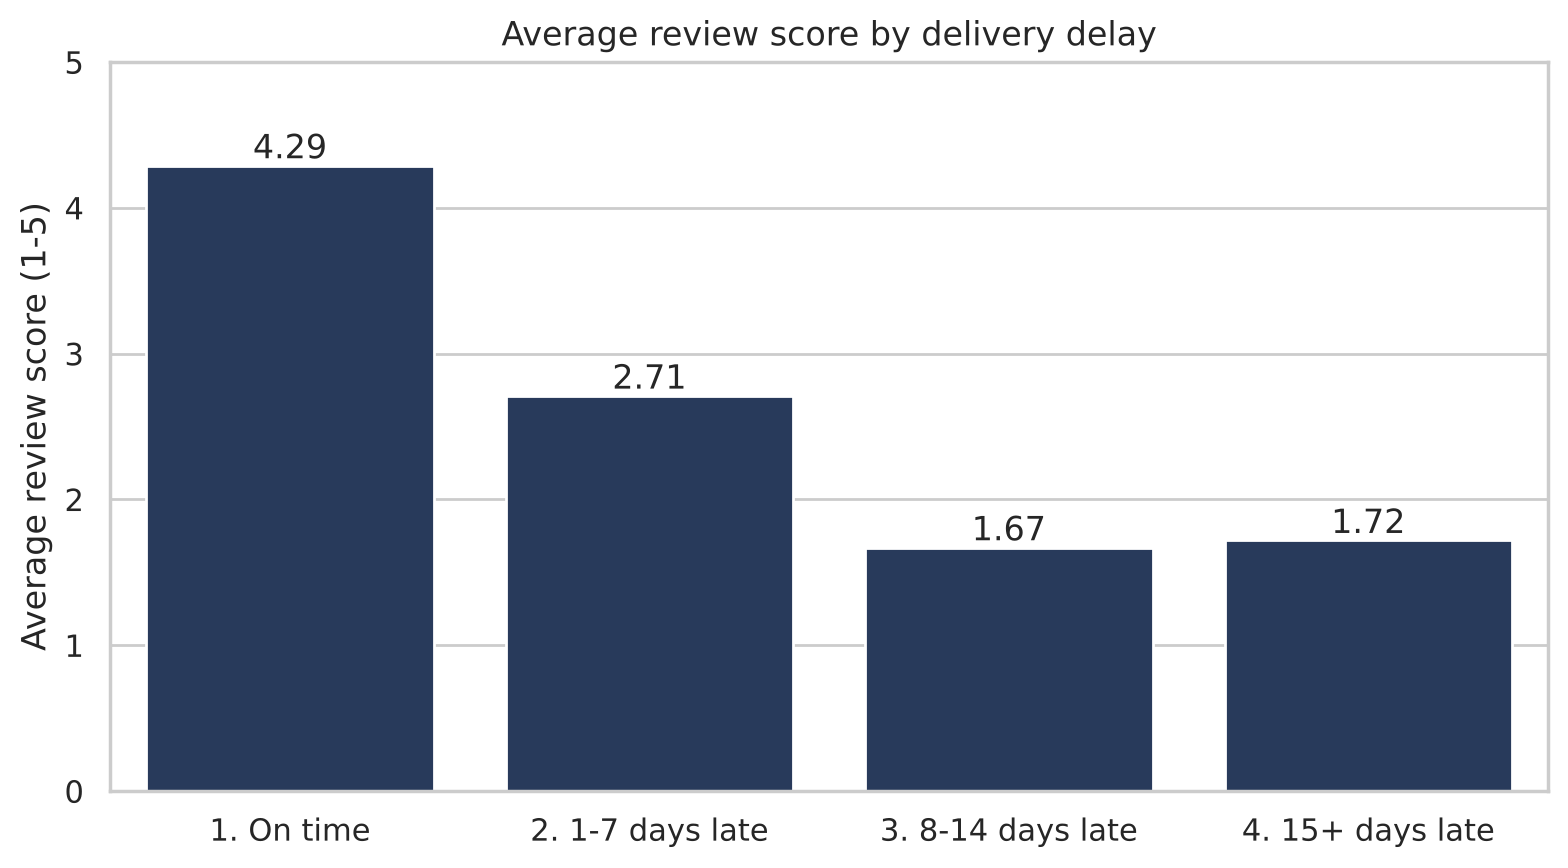

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=q3, x="delivery_status", y="avg_review_score", color=COLOR, ax=ax)
for i, v in enumerate(q3.avg_review_score):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
ax.set_title("Average review score by delivery delay")
ax.set_ylabel("Average review score (1-5)")
ax.set_xlabel("")
ax.set_ylim(0, 5)
plt.tight_layout()
plt.savefig("images/q3_delivery_vs_reviews.png", dpi=150)
plt.show()

### Q4. How many customers come back and buy again?

In [11]:
q4 = q("""
WITH customer_orders AS (
    SELECT c.customer_unique_id,
           COUNT(DISTINCT o.order_id) AS n_orders
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
)
SELECT CASE
           WHEN n_orders = 1 THEN '1 order'
           WHEN n_orders = 2 THEN '2 orders'
           ELSE '3+ orders'
       END                                                 AS customer_group,
       COUNT(*)                                            AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)  AS pct_of_customers
FROM customer_orders
GROUP BY customer_group
ORDER BY customer_group;
""")
q4

,customer_group,customers,pct_of_customers
0,1 order,90315,97.00
1,2 orders,2562,2.75
2,3+ orders,227,0.24


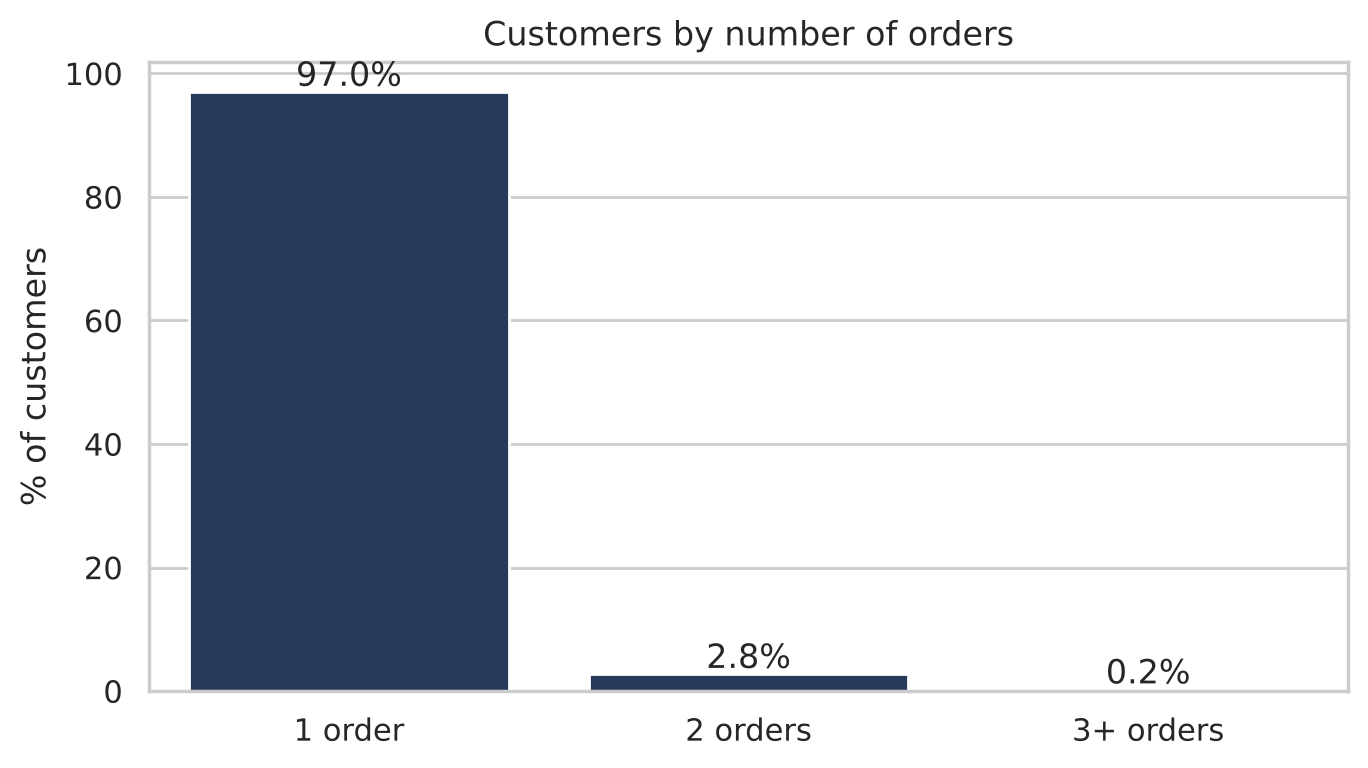

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=q4, x="customer_group", y="pct_of_customers", color=COLOR, ax=ax)
for i, v in enumerate(q4.pct_of_customers):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_title("Customers by number of orders")
ax.set_ylabel("% of customers")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("images/q4_repeat_customers.png", dpi=150)
plt.show()

### Q5. Which payment methods do customers use most?

In [13]:
q5 = q("""
SELECT payment_type,
       COUNT(DISTINCT order_id)                         AS orders,
       ROUND(100.0 * COUNT(DISTINCT order_id)
             / (SELECT COUNT(DISTINCT order_id) FROM payments), 1) AS pct_of_orders,
       ROUND(SUM(payment_value), 2)                     AS total_value,
       ROUND(AVG(payment_installments), 1)              AS avg_installments
FROM payments
WHERE payment_type <> 'not_defined'
GROUP BY payment_type
ORDER BY orders DESC;
""")
q5

,payment_type,orders,pct_of_orders,total_value,avg_installments
0,credit_card,76248,76.9,12493521.71,3.5
1,boleto,19721,19.9,2859682.21,1.0
2,voucher,3836,3.9,373528.59,1.0
3,debit_card,1526,1.5,217748.06,1.0


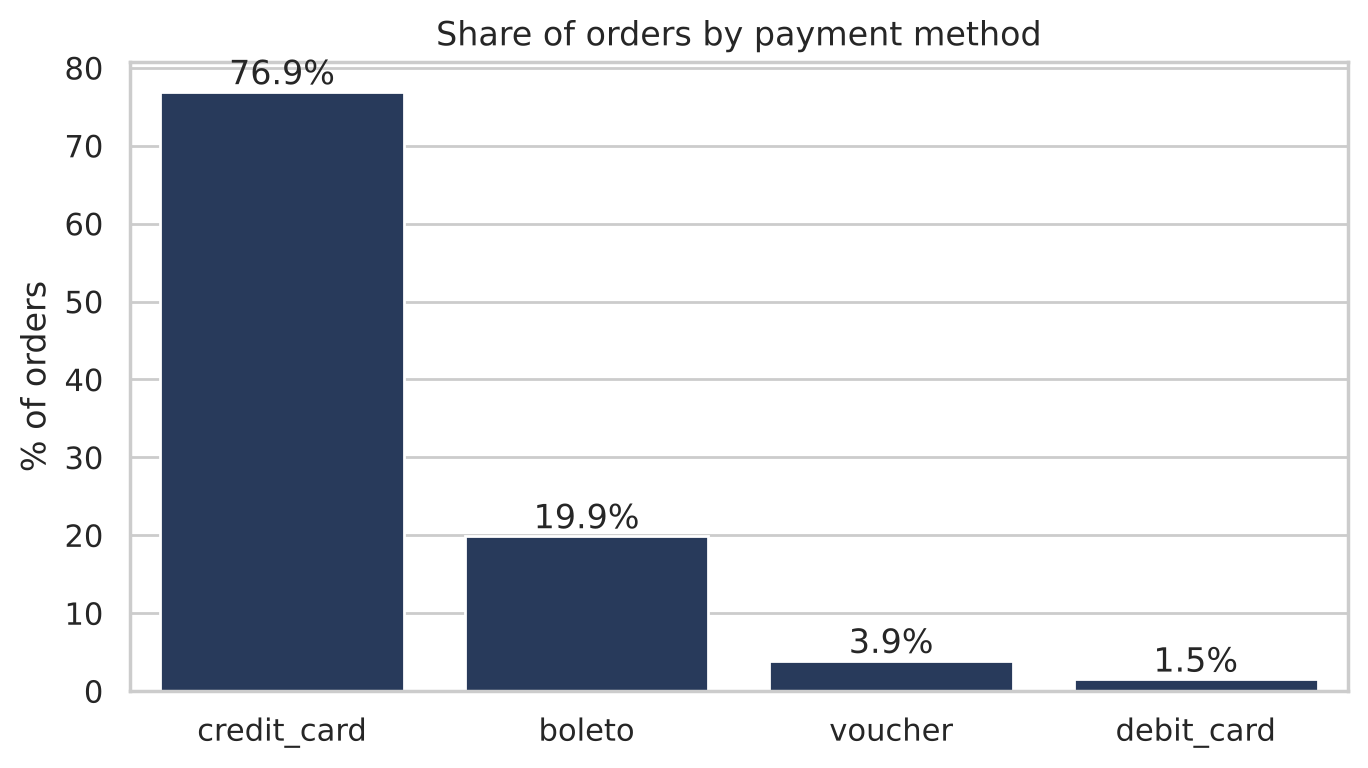

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=q5, x="payment_type", y="pct_of_orders", color=COLOR, ax=ax)
for i, v in enumerate(q5.pct_of_orders):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_title("Share of orders by payment method")
ax.set_ylabel("% of orders")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("images/q5_payment_methods.png", dpi=150)
plt.show()

## 5. Key insights

1. **Late delivery is the main driver of bad reviews.** 6.7% of orders arrived late. The average review score drops from **4.29** (on time) to **2.27** (late), and the share of 1–2 star reviews jumps from **9%** to about **80%** when an order is more than a week late.
2. **Customer retention is very weak.** **97%** of customers bought only once; only **3%** came back for a second order.
3. **Black Friday drives the biggest spike.** November 2017 was the best month (R$ 988K), with revenue up **52%** over October.
4. **Revenue is concentrated.** The top 3 categories (health & beauty, watches & gifts, bed/bath/table) bring **26%** of all revenue.
5. **Customers pay in installments.** Credit cards are used in **77%** of orders, with an average of **3.5** installments.

**Recommendations**
- Fix delivery estimates and track late orders: it is the fastest way to improve ratings.
- Start a loyalty program or follow-up offers to turn one-time buyers into repeat customers.
- Plan stock and marketing early for Black Friday, focused on the top categories.
- Keep installment payment options visible at checkout.
